# 05 · Covariates: the mode where Chronos-2 pulls ahead

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/epjover/chronos2-in-practice/blob/main/notebooks/05_covariates.ipynb)

Companion notebook for *Chronos-2 in Practice (3/7)*.

**What you will learn**

- The difference between a past covariate and a known-future one, which in `predict_df` is
  decided by nothing more than whether a column appears in `future_df`.
- A replication of fev-bench's EPF-DE task (German day-ahead price with the grid operator's
  load and renewable forecasts), checked against the published cutoffs rather than merely
  resembling it.
- How much of the gain comes from *having* the covariate series versus from *knowing its
  future*: three arms on the same task separate the two.
- The same design on Spanish prices as a ladder: nothing, calendar, published day-ahead
  forecasts, past generation.
- What a covariate brings when its future is known for only part of the horizon.
- How much a leak flatters you, measured on purpose: the same ladder with observed values
  passed off as known-future ones.
- That a categorical covariate goes in as a `category` column, and whether the encoding of a
  weekday matters.
- What happens when the covariate is a professional forecast of the target itself: the grid
  operator's day-ahead load forecast, used as a covariate for the load and as a base to correct.

Runtime: ~35 min on a GPU (FAST_MODE: ~4 min), plus a download of the EPF-DE dataset.

In [1]:
# On Google Colab, clone the companion repo and install it (Colab's own PyTorch is kept).
# Locally, `uv sync` already installed everything and this cell does nothing.
import sys

if "google.colab" in sys.modules:
    !git clone --depth 1 https://github.com/epjover/chronos2-in-practice.git
    %cd chronos2-in-practice
    %pip install -q .
    import importlib

    importlib.invalidate_caches()

In [2]:
import time
from dataclasses import replace

import holidays
import numpy as np
import pandas as pd
from huggingface_hub.utils import logging as hub_logging
from IPython.display import Image, display
from transformers.utils import logging as transformers_logging

from c2p.baselines import KnownUntil, PublishedForecast, ResidualForecaster
from c2p.config import get_device, get_paths, is_fast_mode, set_seed
from c2p.data import (
    CALENDAR_COLUMNS,
    add_calendar_features,
    spain_energy_frame,
    validate_and_prepare,
)
from c2p.eval import backtest, error_by_horizon_block, evaluate, skill_table, summarize
from c2p.experiments import (
    DAY_AHEAD_BLOCK,
    FREQ,
    LOAD,
    PRICE,
    TSO_COVARIATES,
    TSO_LOAD_FORECAST,
    day_ahead_config,
)
from c2p.fev_tasks import (
    EPF_DE,
    assert_cutoffs_match,
    load_fev_task,
    task_backtest_config,
    task_series_frame,
)
from c2p.models import Chronos2Forecaster, load_chronos2
from c2p.plots.evaluation import plot_skill_scores
from c2p.plotting import save_figure, set_style
from c2p.results import load_results, run_metadata, save_results
from c2p.schema import ID_COL, TIMESTAMP_COL

FAST_MODE = is_fast_mode(default=False)
PATHS = get_paths(fast_mode=FAST_MODE)
set_seed()
DEVICE = get_device()
set_style()
hub_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

for key, value in run_metadata(device=DEVICE, fast_mode=FAST_MODE).items():
    print(f"{key:>20}: {value}")

              python: 3.11.17
              device: cuda
           fast_mode: False
                seed: 42
          run_at_utc: 2026-11-27 07:11
                 cpu: 12th Gen Intel(R) Core(TM) i9-12900K
     cores_available: 8
       torch_threads: 8
                 gpu: NVIDIA GeForce RTX 3070 (8 GiB)
 chronos-forecasting: 2.3.2
               torch: 2.14.1
              pandas: 3.1.0
               numpy: 2.4.6
                 fev: 0.10.0
       statsforecast: 2.0.1


## 1. One rule, two kinds of covariate

Chronos-2 takes covariates as *series in the same group as the target*. Which kind a column is
depends on one thing only:

- a column of `df` that is **not** in `future_df` is a **past covariate**: the model sees its
  history and nothing after the cutoff;
- a column present in **both** is a **known-future covariate**: the model also sees its values
  across the horizon.

There is no third option and no flag. In this repository the backtest harness makes the choice
explicit instead: only columns listed in `BacktestConfig.known_covariates` are put into the
future frame, and a guard checks that nothing else crossed the cutoff. Everything else in the
frame is a past covariate by construction.

That is also where the most expensive mistake in applied forecasting lives. A "known-future"
covariate must be knowable *at forecast time*: a published day-ahead forecast is, the value that
was eventually observed is not. Section 4 measures what the second one does to your results.

In [3]:
pipeline = load_chronos2(device=DEVICE)
chronos = Chronos2Forecaster(pipeline)

## 2. Replicating EPF-DE from fev-bench

The Chronos-2 paper reports its largest margins on covariate tasks, and EPF-DE is the clearest
of them: the German day-ahead electricity price, forecast 24 hours ahead with two covariates the
market knows in advance: Amprion's load forecast and a combined PV + wind forecast.

"Replicating" it means using the published task, not one that looks like it. `c2p.fev_tasks`
loads the task from the fev-bench task list and restates it as a `BacktestConfig`, then
`assert_cutoffs_match` checks that our 20 windows land on fev's 20 published cutoffs. If the
translation were off by one step, that assertion fails and the replication stops here.

In [4]:
task = load_fev_task(EPF_DE)
epf = task_series_frame(task)
EPF_CONFIG = task_backtest_config(task)
print(f"task:             {task.task_name}")
print(f"target:           {task.target}")
print(f"known covariates: {task.known_dynamic_columns}")
print(
    f"horizon:          {task.horizon} h, {task.num_windows} windows, "
    f"step {task.window_step_size} h, seasonality {task.seasonality}"
)
print(
    f"data:             {len(epf):,} rows, {epf[TIMESTAMP_COL].min()} to {epf[TIMESTAMP_COL].max()}"
)

assert_cutoffs_match(task, epf, EPF_CONFIG)
print("\nOur windows sit on fev's published cutoffs.")

task:             epf_de
target:           target
known covariates: ['Ampirion Load Forecast', 'PV+Wind Forecast']
horizon:          24 h, 20 windows, step 24 h, seasonality 24
data:             52,416 rows, 2012-01-09 00:00:00 to 2017-12-31 23:00:00

Our windows sit on fev's published cutoffs.


Three arms separate two effects that are easy to confuse. `univariate` drops the covariate
columns entirely. `past_only` keeps them in the frame but does not declare them known, so the
model sees their history and stops at the cutoff. `known_future` is the published task: the same
columns, with their horizon values supplied.

If most of the gain appeared in `past_only`, covariates would only be extra context. If it
appears in `known_future`, what the model is using is the future it was handed.

In [5]:
EPF_ARMS = {
    "univariate": (epf[[ID_COL, TIMESTAMP_COL, task.target]], ()),
    "past_only": (epf, ()),
    "known_future": (epf, tuple(task.known_dynamic_columns)),
}
if FAST_MODE:
    EPF_CONFIG = replace(EPF_CONFIG, n_windows=5)

frames = []
for name, (frame, known) in EPF_ARMS.items():
    config = replace(EPF_CONFIG, known_covariates=known)
    model = Chronos2Forecaster(pipeline, name=name)
    metrics = evaluate(backtest(model, frame, config), frame, config)
    frames.append(metrics)
    print(f"  {name:<14} WQL {metrics['WQL'].mean():.4f}  SQL {metrics['SQL'].mean():.4f}")
epf_metrics = pd.concat(frames, ignore_index=True)
print("Saved", save_results(epf_metrics, "05_epf_de_metrics", PATHS).name)

  univariate     WQL 0.4872  SQL 1.0649
  past_only      WQL 0.4286  SQL 0.9380
  known_future   WQL 0.2407  SQL 0.4911
Saved 05_epf_de_metrics.csv


**A check from outside the harness.** `Chronos2Pipeline.predict_fev` is the library's own
route to a fev task: it cuts the windows, forecasts them and returns the predictions in fev's
format, and `task.evaluation_summary` scores them with fev's code. Nothing of `c2p.eval` is
involved. If the replication above is right, its `known_future` arm and this route give the
same numbers, not similar ones.

In [6]:
if FAST_MODE:
    print("Skipped in FAST_MODE: the arms above ran on 5 of the task's 20 windows.")
else:
    predictions, _ = pipeline.predict_fev(task, batch_size=256)
    official = task.evaluation_summary(predictions, model_name="chronos-2")
    ours = load_results("05_epf_de_metrics", PATHS)
    ours = ours[ours["model"] == "known_future"]
    names = ["SQL", "WQL", "MASE", "WAPE"]
    fev_check = pd.DataFrame(
        {
            "metric": names,
            "fev": [official[name] for name in names],
            "harness": [ours[name].mean() for name in names],
        }
    )
    fev_check["difference"] = fev_check["harness"] - fev_check["fev"]
    print(f"task metric: {official['eval_metric']}, {official['num_forecasts']} windows")
    print("Saved", save_results(fev_check, "05_epf_de_fev_check", PATHS).name)
    assert np.allclose(fev_check["fev"], fev_check["harness"], rtol=1e-4), fev_check
    display(fev_check.round(6))

task metric: SQL, 20 windows
Saved 05_epf_de_fev_check.csv


,metric,fev,harness,difference
0,SQL,0.491117,0.491117,-0.0
1,WQL,0.240718,0.240718,-0.0
2,MASE,0.604226,0.604226,0.0
3,WAPE,0.291017,0.291017,0.0


Saved 05_epf_de_skill.csv


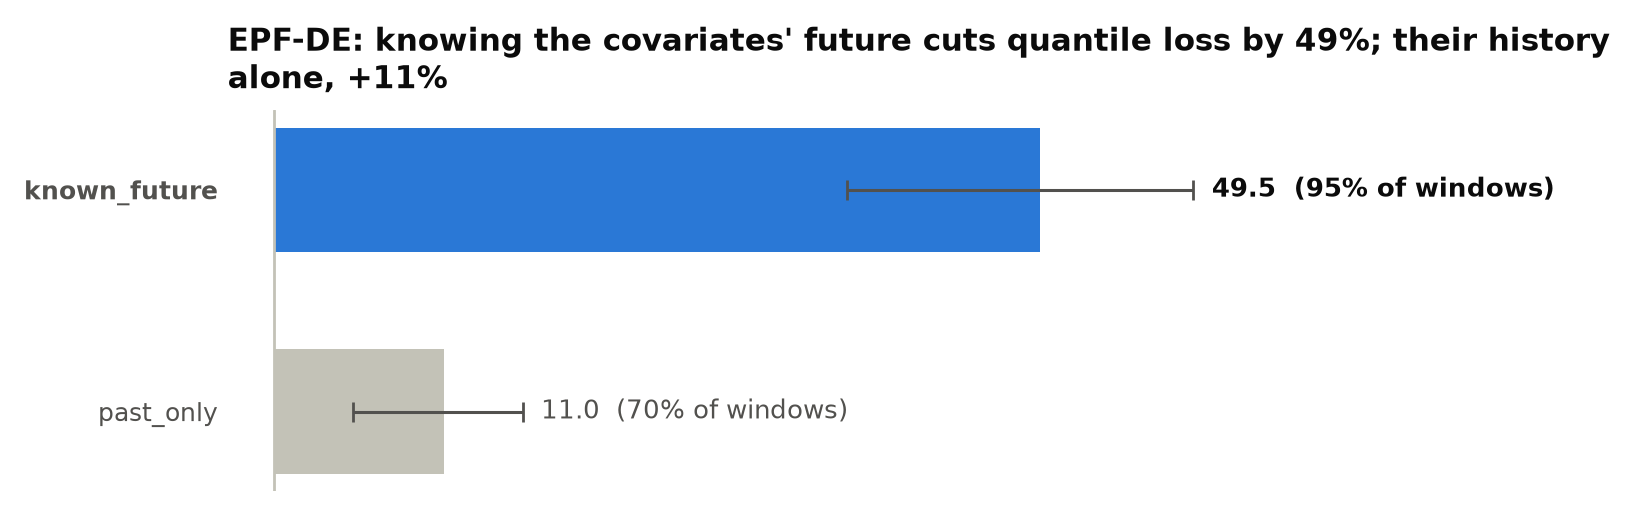

In [7]:
epf_metrics = load_results("05_epf_de_metrics", PATHS)
epf_skill = skill_table(epf_metrics, baseline="univariate", metric="WQL", aggregate="both")
print("Saved", save_results(epf_skill, "05_epf_de_skill", PATHS).name)

known = epf_skill.set_index("model").loc["known_future"]
past = epf_skill.set_index("model").loc["past_only"]
title = (
    f"EPF-DE: knowing the covariates' future cuts quantile loss by {known['skill']:.0%}; "
    f"their history alone, {past['skill']:+.0%}"
)
ax = plot_skill_scores(
    epf_skill,
    highlight="known_future",
    title=title,
    xlabel="WQL improvement over the univariate task (%)",
)
(figure_path,) = save_figure(ax.figure, "05_epf_de_covariates", PATHS.figures)
display(Image(filename=figure_path, width=800))

## 3. The same design on Spanish prices

The Spanish dataset carries the equivalent covariates: the grid operator publishes day-ahead
forecasts of load, solar and onshore wind the day before, so for a horizon that ends within the
next day they are legitimately known at forecast time.

The target needs one paragraph, because the dataset's column names invite a mistake. The table
has `price actual` and `price day ahead`, and describes the second as a forecast.
`scripts/check_price_columns.py` compares both with the hourly day-ahead price that OMIE, the
market operator, publishes for 2018 (`results/05_price_columns.csv`). `price actual` follows
OMIE's day-ahead price with a correlation of 0.99 and sits about 6 EUR/MWh above it: it is the
final price, the day-ahead price plus the system costs added after the auction. The
`price day ahead` column equals OMIE's price to the cent on 233 of the 365 days and holds other
values on the rest, so it is used here neither as a covariate nor as a reference. The target is
`price actual`, and forecasting it a day ahead is, for almost all of its variation, the
day-ahead price forecasting problem. Read the section as that.

The ladder adds one kind of information at a time, so each rung is attributable:

| Rung | Added |
| --- | --- |
| `none` | nothing: the price history alone |
| `+calendar` | hour, day of week, month, weekend and Spanish holidays, as known-future |
| `+TSO forecasts` | the operator's day-ahead load, solar and wind forecasts, as known-future |
| `TSO forecasts, no calendar` | the same three forecasts without the calendar: it says whether the calendar adds anything once the forecasts are there |
| `+past generation` | actual generation by source, as **past-only** covariates |
| `LEAK: observed as known` | the same quantities, but **observed** values handed over as if known |
| `LEAK: the target itself` | a copy of the price, declared known-future (the unmistakable case) |

Note what is *not* compared: the price error in EUR/MWh against the German task above. Different
markets, different price levels, different years. Only the relative improvement travels.

In [8]:
COLUMNS = [ID_COL, TIMESTAMP_COL, PRICE, *TSO_COVARIATES]
LEAK_COLUMNS = ("load_actual", "gen_solar", "gen_wind_onshore")
PAST_COLUMNS = ("gen_solar", "gen_wind_onshore", "gen_nuclear", "gen_fossil_gas")
raw = spain_energy_frame()
price, price_report = validate_and_prepare(
    raw[[*COLUMNS, *dict.fromkeys([*LEAK_COLUMNS, *PAST_COLUMNS])]], freq=FREQ, target=PRICE
)
price = add_calendar_features(price)
price["price_leak"] = price[PRICE]  # a copy of the target, for the leak demonstration below
CALENDAR = tuple(CALENDAR_COLUMNS)
print(price_report)
print(f"\nCalendar covariates: {CALENDAR}")
print(f"TSO day-ahead forecasts: {TSO_COVARIATES}")

DataReport (freq='h', 1 series)
  rows in -> out:              35,064 -> 35,064
  duplicated rows resolved:    0
  sentinel values -> NaN:      0
  missing timestamps inserted: 0
  rows trimmed (max_length):   0
  missing values after prep:   load_actual=36, gen_solar=18, gen_wind_onshore=18, gen_nuclear=17, gen_fossil_gas=18
  short series:                none
  note: Timestamps are timezone-naive and no source_tz was given: assumed to be UTC.

Calendar covariates: ('hour', 'day_of_week', 'month', 'is_weekend', 'is_holiday')
TSO day-ahead forecasts: ('load_forecast_tso', 'solar_forecast_tso', 'wind_onshore_forecast_tso')


In [9]:
LADDER = {
    "none": {"columns": (), "known": ()},
    "+calendar": {"columns": CALENDAR, "known": CALENDAR},
    "+TSO forecasts": {
        "columns": (*CALENDAR, *TSO_COVARIATES),
        "known": (*CALENDAR, *TSO_COVARIATES),
    },
    "TSO forecasts, no calendar": {"columns": TSO_COVARIATES, "known": TSO_COVARIATES},
    "+past generation": {
        "columns": (*CALENDAR, *TSO_COVARIATES, *PAST_COLUMNS),
        "known": (*CALENDAR, *TSO_COVARIATES),
    },
    "LEAK: observed as known": {
        "columns": (*CALENDAR, *LEAK_COLUMNS),
        "known": (*CALENDAR, *LEAK_COLUMNS),
    },
    "LEAK: the target itself": {
        "columns": (*CALENDAR, "price_leak"),
        "known": (*CALENDAR, "price_leak"),
    },
}

start = time.perf_counter()
frames = []
for name, spec in LADDER.items():
    frame = price[[ID_COL, TIMESTAMP_COL, PRICE, *spec["columns"]]]
    config = day_ahead_config(
        FAST_MODE, target=PRICE, known_covariates=spec["known"], max_context=2048
    )
    model = Chronos2Forecaster(pipeline, name=name)
    metrics = evaluate(backtest(model, frame, config), frame, config)
    frames.append(metrics)
    print(
        f"  {name:<24} WQL {metrics['WQL'].mean():.4f}  cov80 {metrics['coverage_80'].mean():.1%}"
    )
ladder = pd.concat(frames, ignore_index=True)
print(
    f"{len(LADDER)} rungs x {config.n_windows} windows in "
    f"{(time.perf_counter() - start) / 60:.1f} min"
)
print("Saved", save_results(ladder, "05_price_ladder_metrics", PATHS).name)

  none                     WQL 0.0499  cov80 77.8%
  +calendar                WQL 0.0503  cov80 77.2%
  +TSO forecasts           WQL 0.0467  cov80 74.9%
  TSO forecasts, no calendar WQL 0.0440  cov80 77.9%
  +past generation         WQL 0.0463  cov80 78.1%
  LEAK: observed as known  WQL 0.0473  cov80 74.8%
  LEAK: the target itself  WQL 0.0069  cov80 75.7%
7 rungs x 365 windows in 3.3 min
Saved 05_price_ladder_metrics.csv


In [10]:
ladder = load_results("05_price_ladder_metrics", PATHS)
ladder_skill = skill_table(
    ladder, baseline="none", metric="WQL", block_length=DAY_AHEAD_BLOCK, aggregate="both"
)
print("Saved", save_results(ladder_skill, "05_price_ladder_skill", PATHS).name)
ladder_skill.round(4)

Saved 05_price_ladder_skill.csv


,model,baseline,metric,skill,ci_low,ci_high,win_rate,n_units,block_length,total_skill,total_ci_low,total_ci_high
0,LEAK: the target itself,none,WQL,0.8333,0.8226,0.8440,1.0000,365,7,0.8623,0.8446,0.8786
1,+past generation,none,WQL,0.1175,0.0756,0.1562,0.6795,365,7,0.0724,-0.0438,0.1599
2,"TSO forecasts, no calendar",none,WQL,0.1091,0.0625,0.1514,0.6575,365,7,0.1184,0.0557,0.1776
3,+TSO forecasts,none,WQL,0.0831,0.0425,0.1199,0.6384,365,7,0.0646,0.0042,0.1261
4,LEAK: observed as known,none,WQL,0.0731,0.0338,0.1084,0.6493,365,7,0.0525,-0.0135,0.1163
5,none,none,WQL,0.0000,0.0000,0.0000,0.5000,365,7,0.0000,0.0000,0.0000
6,+calendar,none,WQL,-0.0018,-0.0168,0.0121,0.4630,365,7,-0.0084,-0.0485,0.0287


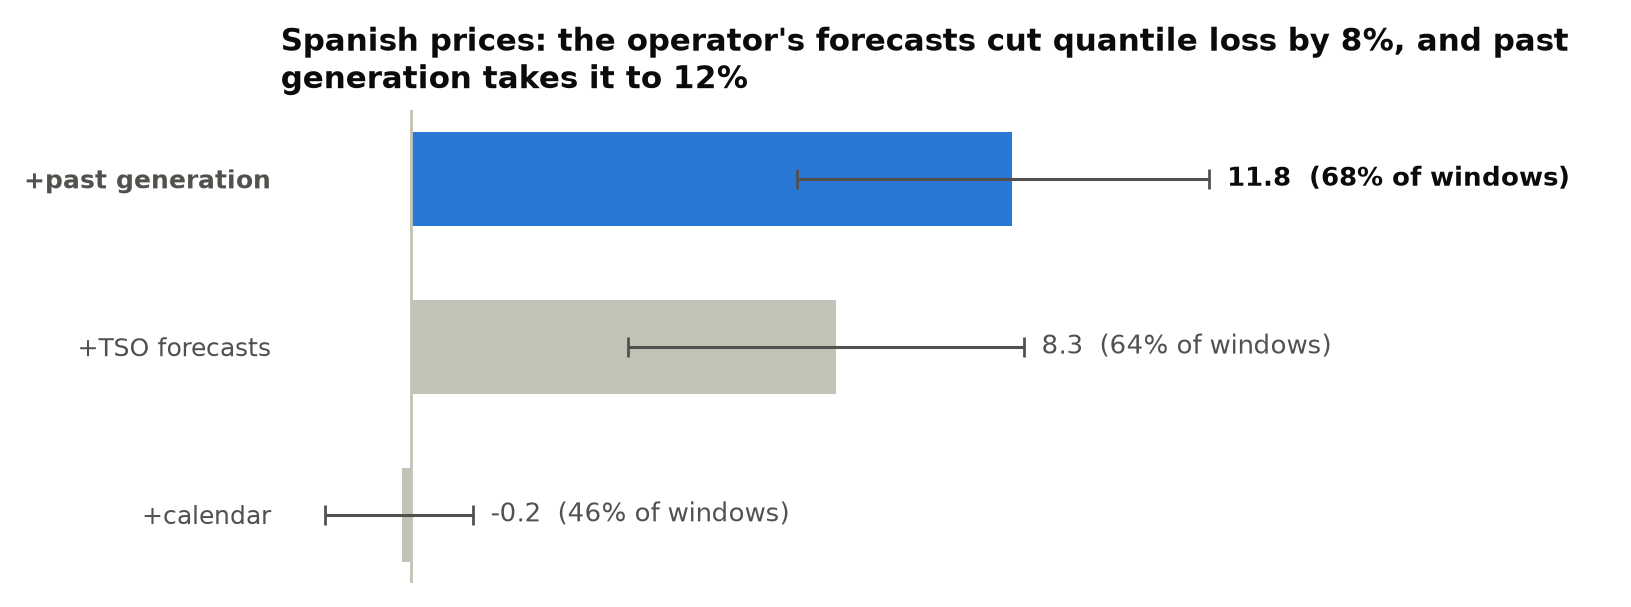

In [11]:
ladder_skill = load_results("05_price_ladder_skill", PATHS)
# The two LEAK arms are quantified in section 4; at +83% they would flatten every other bar.
rungs = ladder_skill[~ladder_skill["model"].str.startswith("LEAK")]
rungs = rungs[rungs["model"] != "TSO forecasts, no calendar"]  # a control, not a rung
best = rungs.iloc[0]
tso = rungs.set_index("model").loc["+TSO forecasts"]
title = (
    f"Spanish prices: the operator's forecasts cut quantile loss by {tso['skill']:.0%}, "
    f"and past generation takes it to {best['skill']:.0%}"
)
ax = plot_skill_scores(
    rungs,
    highlight=str(best["model"]),
    title=title,
    xlabel="WQL improvement over no covariates (%)",
)
(figure_path,) = save_figure(ax.figure, "05_covariate_ladder", PATHS.figures)
display(Image(filename=figure_path, width=800))

### A covariate known for part of the horizon

The ladder assumes the operator's forecasts cover all 24 hours. Often a covariate's own forecast
is shorter than the horizon: a weather forecast that stops, a promotion calendar that ends with
the month. `predict_df` has an answer for that, and no flag for it either: a NaN in `future_df`
means "not known at this step". A `future_df` that is NaN everywhere gives the same forecast as
no `future_df` at all.

`KnownUntil` hides the future covariates after a given step, so the same three operator
forecasts can be given three ways: their history only (hidden from step 1), known for the first
12 hours, known for all 24. The reference is the price with no covariates at all, as in the
ladder. The hours are scored in two blocks, 1 to 12 and 13 to 24, because the question is what
happens in the hours the covariate does not reach.

In [12]:
HALF = 12
NONE, PAST_ONLY = "no covariates", "history only"
FIRST_HALF, WHOLE = f"known for {HALF} h", f"known for {2 * HALF} h"
with_forecasts = price[[ID_COL, TIMESTAMP_COL, PRICE, *TSO_COVARIATES]]
known_config = day_ahead_config(
    FAST_MODE, target=PRICE, known_covariates=TSO_COVARIATES, max_context=2048
)
plain_config = day_ahead_config(FAST_MODE, target=PRICE, max_context=2048)
PARTIAL_ARMS = [
    (Chronos2Forecaster(pipeline, name=NONE), price[[ID_COL, TIMESTAMP_COL, PRICE]], plain_config),
    (KnownUntil(Chronos2Forecaster(pipeline), 0, name=PAST_ONLY), with_forecasts, known_config),
    (
        KnownUntil(Chronos2Forecaster(pipeline), HALF, name=FIRST_HALF),
        with_forecasts,
        known_config,
    ),
    (Chronos2Forecaster(pipeline, name=WHOLE), with_forecasts, known_config),
]
forecasts, metrics = [], []
for model, frame, config in PARTIAL_ARMS:
    forecasts.append(backtest(model, frame, config))
    metrics.append(evaluate(forecasts[-1], frame, config))
print(
    "Saved", save_results(pd.concat(metrics, ignore_index=True), "05_partial_metrics", PATHS).name
)
partial_blocks = error_by_horizon_block(
    pd.concat(forecasts, ignore_index=True), edges=(HALF, 2 * HALF)
)
print("Saved", save_results(partial_blocks, "05_partial_blocks", PATHS).name)

partial_blocks = load_results("05_partial_blocks", PATHS)
scored = {f"1-{2 * HALF}": load_results("05_partial_metrics", PATHS)}
scored |= {str(block): rows for block, rows in partial_blocks.groupby("block", observed=True)}
partial_skill = pd.concat(
    [
        skill_table(rows, baseline=NONE, metric="WQL", block_length=DAY_AHEAD_BLOCK)
        .assign(hours=hours)
        .merge(rows.groupby("model", as_index=False)["WQL"].mean(), on="model")
        for hours, rows in scored.items()
    ],
    ignore_index=True,
)
print("Saved", save_results(partial_skill, "05_partial_skill", PATHS).name)
partial_skill.set_index(["hours", "model"])[
    ["WQL", "skill", "ci_low", "ci_high", "win_rate"]
].round(4)

Saved 05_partial_metrics.csv
Saved 05_partial_blocks.csv
Saved 05_partial_skill.csv


WQL   skill  ci_low  ci_high  win_rate
hours model                                                    
1-24  known for 24 h  0.0440  0.1091  0.0625   0.1514    0.6575
      known for 12 h  0.0465  0.0522  0.0177   0.0866    0.5753
      history only    0.0493  0.0034 -0.0140   0.0215    0.5151
      no covariates   0.0499  0.0000  0.0000   0.0000    0.5000
1-12  known for 12 h  0.0431  0.0630  0.0185   0.1050    0.6137
      known for 24 h  0.0433  0.0628  0.0091   0.1124    0.6082
      history only    0.0456  0.0111 -0.0124   0.0341    0.5068
      no covariates   0.0459  0.0000  0.0000   0.0000    0.5000
13-24 known for 24 h  0.0453  0.1490  0.0970   0.1961    0.6658
      known for 12 h  0.0503  0.0443  0.0085   0.0787    0.5699
      no covariates   0.0544  0.0000  0.0000   0.0000    0.5000
      history only    0.0535 -0.0052 -0.0266   0.0159    0.5233

## 4. The trap, and what it looks like in numbers

The mistake every covariate pipeline can make is handing the model a column that is only known
*after* the fact. Nothing in the API objects (the leak is in the data, not in the call), so the
only defence is knowing what a leak looks like in the results.

Two arms probe it, and they do not agree, which is the interesting part:

- `LEAK: observed as known` replaces the operator's published forecasts with the values that
  were observed afterwards. On this market that changes very little, and the reason is economic
  rather than statistical: the target is almost entirely the day-ahead price (section 3), and
  the day-ahead price is *cleared against the day-ahead forecasts*. The published forecast is
  not a noisy proxy for the outcome; it is close to the input the market used. A leak
  is not automatically an advantage.
- `LEAK: the target itself` hands over a copy of the price as a known-future covariate. That is
  what a leak looks like when it bites, and the number below is the signature to watch for.

The practical rule is therefore not "leaks inflate results by X%" but: an implausibly large gain
from a covariate is a reason to audit the column, not to publish it. And when a covariate exists
in both a forecast and an observed version, prefer the forecast, not only because it is the one you will have,
but because on this dataset it is also the more informative one.

In [13]:
ladder_skill = load_results("05_price_ladder_skill", PATHS).set_index("model")
honest = ladder_skill.loc["+TSO forecasts", "skill"]
observed = ladder_skill.loc["LEAK: observed as known", "skill"]
target_leak = ladder_skill.loc["LEAK: the target itself", "skill"]
print(
    f"Published day-ahead forecasts, known-future: {honest:+7.1%}\n"
    f"Observed values passed off as known:         {observed:+7.1%}  "
    f"({100 * (observed - honest):+.1f} points vs the honest arm)\n"
    f"The target itself, passed off as known:      {target_leak:+7.1%}  "
    f"<- the signature of a real leak"
)

Published day-ahead forecasts, known-future:   +8.3%
Observed values passed off as known:           +7.3%  (-1.0 points vs the honest arm)
The target itself, passed off as known:       +83.3%  <- the signature of a real leak


## 5. Holidays, measured where they happen

The calendar rung above bundles five features, and four of them are *periodic*: hour, weekday,
month, weekend. The model can read all four off 2,048 hours of price history, so a null result
for the bundle says little about the fifth, `is_holiday`, which is the one thing positions cannot
encode. 2018 has ten national holidays, so ten of the 365 windows forecast a holiday, too few
to move the yearly skill score whatever happens on them.

Two things settle it. A rung with *only* the holiday flag, so nothing periodic dilutes it; and the
skill of both calendar rungs split by whether the window's horizon is a holiday. The horizon of a
22:00 UTC cutoff is the next local day, so a window is a holiday window when that day is in the
national calendar.


In [14]:
HOLIDAY_ARM = "+holiday flag only"
holiday_frame = price[[ID_COL, TIMESTAMP_COL, PRICE, "is_holiday"]]
holiday_config = day_ahead_config(
    FAST_MODE, target=PRICE, known_covariates=("is_holiday",), max_context=2048
)
holiday_metrics = evaluate(
    backtest(Chronos2Forecaster(pipeline, name=HOLIDAY_ARM), holiday_frame, holiday_config),
    holiday_frame,
    holiday_config,
)
ladder = load_results("05_price_ladder_metrics", PATHS)
arms = pd.concat(
    [ladder[ladder["model"].isin(["none", "+calendar"])], holiday_metrics], ignore_index=True
)

# A window forecasts a holiday when its horizon's local date is in the national calendar.
horizon_day = (
    (pd.to_datetime(arms["cutoff"]) + pd.Timedelta(hours=2))
    .dt.tz_localize("UTC")
    .dt.tz_convert("Europe/Madrid")
    .dt.normalize()
    .dt.tz_localize(None)
)
holiday_dates = pd.to_datetime(list(holidays.country_holidays("ES", years=[2018])))
arms["holiday_window"] = horizon_day.isin(holiday_dates)
n_holiday = int(arms.loc[arms["model"] == "none", "holiday_window"].sum())
print(f"{n_holiday} holiday windows among {holiday_config.n_windows}")

subsets = {
    "all windows": arms,
    "holiday windows": arms[arms["holiday_window"]],
    "ordinary windows": arms[~arms["holiday_window"]],
}
# The ten holiday windows are scattered over the year, so they are resampled one by one;
# the other two subsets are (nearly) consecutive days and are resampled in blocks.
holiday_skill = pd.concat(
    [
        skill_table(
            subset,
            baseline="none",
            metric="WQL",
            block_length=1 if name == "holiday windows" else DAY_AHEAD_BLOCK,
        ).assign(windows=name)
        for name, subset in subsets.items()
    ],
    ignore_index=True,
)
holiday_skill = holiday_skill[holiday_skill["model"] != "none"]
print("Saved", save_results(holiday_skill, "05_holiday_windows", PATHS).name)
for name, subset in subsets.items():
    print(f"\n{name} ({subset['window'].nunique()} windows), WQL vs no covariates:")
    rows = holiday_skill[holiday_skill["windows"] == name].set_index("model")
    for model in (HOLIDAY_ARM, "+calendar"):
        row = rows.loc[model]
        print(
            f"  {model:<20} {row['skill']:+7.1%}  [{row['ci_low']:+.1%}, {row['ci_high']:+.1%}]  "
            f"win {row['win_rate']:.0%}"
        )

10 holiday windows among 365
Saved 05_holiday_windows.csv

all windows (365 windows), WQL vs no covariates:
  +holiday flag only     -0.4%  [-1.7%, +0.8%]  win 47%
  +calendar              -0.2%  [-1.7%, +1.2%]  win 46%

holiday windows (10 windows), WQL vs no covariates:
  +holiday flag only    +14.0%  [+4.9%, +22.8%]  win 80%
  +calendar             +12.3%  [-1.9%, +22.6%]  win 70%

ordinary windows (355 windows), WQL vs no covariates:
  +holiday flag only     -0.9%  [-2.1%, +0.4%]  win 46%
  +calendar              -0.6%  [-2.0%, +0.7%]  win 46%


## 6. A categorical covariate

Chronos-2 takes categorical covariates as well as numeric ones, and `predict_df` decides which
is which from the column's dtype: a `category` (or string) column is encoded per series before
it reaches the model, a float column goes in as a number. The weekday is a clean test of
whether that choice matters, because it can be written either way: as the number 0 to 6, which
tells the model that Sunday is "six times" Monday, or as seven unordered labels.

Both arms add the weekday of every hour as a known-future covariate to the price history.

In [15]:
WEEKDAY_NAMES = np.array(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
weekday_frame = price[[ID_COL, TIMESTAMP_COL, PRICE, "day_of_week"]].copy()
weekday_frame["weekday"] = pd.Categorical(
    WEEKDAY_NAMES[weekday_frame["day_of_week"].astype(int)], categories=WEEKDAY_NAMES
)
CATEGORICAL_ARMS = {"+weekday as a number": "day_of_week", "+weekday as a category": "weekday"}

ladder = load_results("05_price_ladder_metrics", PATHS)
frames = [ladder[ladder["model"] == "none"]]
for name, column in CATEGORICAL_ARMS.items():
    frame = weekday_frame[[ID_COL, TIMESTAMP_COL, PRICE, column]]
    config = day_ahead_config(FAST_MODE, target=PRICE, known_covariates=(column,), max_context=2048)
    model = Chronos2Forecaster(pipeline, name=name)
    frames.append(evaluate(backtest(model, frame, config), frame, config))
    print(f"  {name:<24} dtype {frame[column].dtype!s:<9} WQL {frames[-1]['WQL'].mean():.4f}")
categorical = pd.concat(frames, ignore_index=True)
print("Saved", save_results(categorical, "05_categorical_metrics", PATHS).name)

categorical_skill = skill_table(
    load_results("05_categorical_metrics", PATHS),
    baseline="none",
    metric="WQL",
    block_length=DAY_AHEAD_BLOCK,
)
print("Saved", save_results(categorical_skill, "05_categorical_skill", PATHS).name)
categorical_skill.round(4)

  +weekday as a number     dtype float64   WQL 0.0508
  +weekday as a category   dtype category  WQL 0.0505
Saved 05_categorical_metrics.csv
Saved 05_categorical_skill.csv


,model,baseline,metric,skill,ci_low,ci_high,win_rate,n_units,block_length
0,none,none,WQL,0.0000,0.0000,0.0000,0.5000,365,7
1,+weekday as a category,none,WQL,-0.0084,-0.0210,0.0052,0.4466,365,7
2,+weekday as a number,none,WQL,-0.0113,-0.0249,0.0041,0.4384,365,7


## 7. Load: when the covariate is a professional forecast of the target

Notebook 02 put the operator's day-ahead load forecast in the table as a reference, and it was
several times more accurate than any model there. That forecast is public before the cutoff,
so it is also a legitimate known-future covariate for the load. Three ways to use it:

- **History only**: the zero-shot forecast of notebook 02, as the starting point.
- **As a covariate**: the operator's forecast in `future_df`. The model has to work out, from
  the context alone, that this column is nearly the target.
- **Correct it**: forecast what the operator got wrong (`load - operator forecast`) with
  Chronos-2 on its own, and add the operator's forecast back (`ResidualForecaster`). The
  operator carries the level and the shape; the model only has to find out whether the
  operator's errors persist from one day to the next.

The fourth row is the operator's forecast itself. It is the row to beat, and a point forecast:
its WQL equals its WAPE and its coverage is not meaningful. That makes WQL an uneven
comparison (a model that states its uncertainty is scored on its quantiles, the operator on a
single number), so the table reports the skill twice: on WQL, and on WAPE, where both sides
are judged as point forecasts.

In [16]:
load_frame, _ = validate_and_prepare(
    raw[[ID_COL, TIMESTAMP_COL, LOAD, TSO_LOAD_FORECAST]], freq=FREQ, target=LOAD
)
history_frame = load_frame[[ID_COL, TIMESTAMP_COL, LOAD]]
plain_config = day_ahead_config(FAST_MODE, max_context=2048)
known_config = day_ahead_config(FAST_MODE, known_covariates=(TSO_LOAD_FORECAST,), max_context=2048)
OPERATOR = "operator forecast"
OPERATOR_ARMS = {
    "history only": (
        Chronos2Forecaster(pipeline, name="history only"),
        history_frame,
        plain_config,
    ),
    "operator forecast as covariate": (
        Chronos2Forecaster(pipeline, name="operator forecast as covariate"),
        load_frame,
        known_config,
    ),
    "operator forecast, corrected": (
        ResidualForecaster(chronos, TSO_LOAD_FORECAST, name="operator forecast, corrected"),
        load_frame,
        known_config,
    ),
    OPERATOR: (PublishedForecast(TSO_LOAD_FORECAST, name=OPERATOR), load_frame, known_config),
}
frames = []
for name, (model, frame, config) in OPERATOR_ARMS.items():
    frames.append(evaluate(backtest(model, frame, config), frame, config))
    print(f"  {name:<32} WQL {frames[-1]['WQL'].mean():.4f}  WAPE {frames[-1]['WAPE'].mean():.2%}")
operator_metrics = pd.concat(frames, ignore_index=True)
print("Saved", save_results(operator_metrics, "05_operator_metrics", PATHS).name)

  history only                     WQL 0.0388  WAPE 4.67%
  operator forecast as covariate   WQL 0.0103  WAPE 1.28%
  operator forecast, corrected     WQL 0.0074  WAPE 0.93%
  operator forecast                WQL 0.0094  WAPE 0.94%
Saved 05_operator_metrics.csv


In [17]:
operator_metrics = load_results("05_operator_metrics", PATHS)
operator_skill = skill_table(
    operator_metrics,
    baseline=OPERATOR,
    metric="WQL",
    block_length=DAY_AHEAD_BLOCK,
    aggregate="both",
)
print("Saved", save_results(operator_skill, "05_operator_skill", PATHS).name)
# The same comparison as point forecasts: the fair one against a forecast with no quantiles.
operator_point_skill = skill_table(
    operator_metrics,
    baseline=OPERATOR,
    metric="WAPE",
    block_length=DAY_AHEAD_BLOCK,
    aggregate="both",
)
print("Saved", save_results(operator_point_skill, "05_operator_point_skill", PATHS).name)

means = summarize(operator_metrics).set_index("model")
skill = operator_skill.set_index("model")
point_skill = operator_point_skill.set_index("model")


def versus_operator(row: pd.Series) -> str:
    """Skill against the operator's forecast with its interval, as text."""
    return f"{row['skill']:+6.1%} [{row['ci_low']:+.1%}, {row['ci_high']:+.1%}]"


print(
    f"{'arm':<32} {'WQL':>7} {'WAPE':>7} {'cov80':>6}  "
    f"{'WQL vs operator':<24} {'WAPE vs operator':<24}"
)
for name in OPERATOR_ARMS:
    row = means.loc[name]
    is_operator = name == OPERATOR
    coverage = "n/a" if is_operator else f"{row['coverage_80']:.1%}"
    on_wql = "n/a" if is_operator else versus_operator(skill.loc[name])
    on_wape = "n/a" if is_operator else versus_operator(point_skill.loc[name])
    print(
        f"{name:<32} {row['WQL']:7.4f} {row['WAPE']:7.2%} {coverage:>6}  {on_wql:<24} {on_wape:<24}"
    )

Saved 05_operator_skill.csv
Saved 05_operator_point_skill.csv
arm                                  WQL    WAPE  cov80  WQL vs operator          WAPE vs operator        
history only                      0.0388   4.67%  73.4%  -169.4% [-229.6%, -119.7%] -223.5% [-297.5%, -163.2%]
operator forecast as covariate    0.0103   1.28%  67.2%   -7.8% [-13.9%, -2.1%]   -35.6% [-43.3%, -28.4%] 
operator forecast, corrected      0.0074   0.93%  78.1%  +21.4% [+19.4%, +23.3%]   +1.6% [-0.9%, +4.0%]   
operator forecast                 0.0094   0.94%    n/a  n/a                      n/a                     


## 8. What Chronos-2 will not take

One limit needs stating plainly, because it bounds everything above: Chronos-2 accepts
**numeric and categorical covariates only**. There is no text input. A promotion's description,
an incident report, a weather warning in words: none of it goes in, and the paper names
multimodal inputs as future work rather than a feature.

In practice that means the engineering job is turning what you know into numbers and categories:
a holiday becomes a flag, a tariff becomes a level, a published forecast becomes a column. The
ladder above is that job, done once.

## Summary

In [18]:
epf_skill = load_results("05_epf_de_skill", PATHS).set_index("model")
ladder_skill = load_results("05_price_ladder_skill", PATHS).set_index("model")

print("EPF-DE (fev-bench task, 20 published windows), WQL vs the univariate task:")
for model in ("past_only", "known_future"):
    row = epf_skill.loc[model]
    print(
        f"  {model:<14} {row['skill']:+7.1%}  [{row['ci_low']:+.1%}, {row['ci_high']:+.1%}]  "
        f"win {row['win_rate']:.0%}"
    )

print("\nSpanish price, WQL vs no covariates:")
for model in ladder_skill.index:
    row = ladder_skill.loc[model]
    print(
        f"  {model:<24} {row['skill']:+7.1%}  [{row['ci_low']:+.1%}, {row['ci_high']:+.1%}]  "
        f"win {row['win_rate']:.0%}"
    )

print("\nWeekday as a known-future covariate of the price, WQL vs no covariates:")
categorical_skill = load_results("05_categorical_skill", PATHS).set_index("model")
for model in CATEGORICAL_ARMS:
    row = categorical_skill.loc[model]
    print(
        f"  {model:<24} {row['skill']:+7.1%}  [{row['ci_low']:+.1%}, {row['ci_high']:+.1%}]  "
        f"win {row['win_rate']:.0%}"
    )

print("\nSpanish load against the operator's published forecast, on WQL and as point forecasts:")
operator_skill = load_results("05_operator_skill", PATHS).set_index("model")
operator_point_skill = load_results("05_operator_point_skill", PATHS).set_index("model")
for model in OPERATOR_ARMS:
    if model != OPERATOR:
        row, point = operator_skill.loc[model], operator_point_skill.loc[model]
        print(
            f"  {model:<32} WQL {row['skill']:+7.1%} [{row['ci_low']:+.1%}, {row['ci_high']:+.1%}]"
            f"   WAPE {point['skill']:+7.1%} [{point['ci_low']:+.1%}, {point['ci_high']:+.1%}]"
        )

EPF-DE (fev-bench task, 20 published windows), WQL vs the univariate task:
  past_only       +11.0%  [+5.1%, +16.1%]  win 70%
  known_future    +49.5%  [+37.0%, +59.4%]  win 95%

Spanish price, WQL vs no covariates:
  LEAK: the target itself   +83.3%  [+82.3%, +84.4%]  win 100%
  +past generation          +11.8%  [+7.6%, +15.6%]  win 68%
  TSO forecasts, no calendar  +10.9%  [+6.2%, +15.1%]  win 66%
  +TSO forecasts             +8.3%  [+4.2%, +12.0%]  win 64%
  LEAK: observed as known    +7.3%  [+3.4%, +10.8%]  win 65%
  none                       +0.0%  [+0.0%, +0.0%]  win 50%
  +calendar                  -0.2%  [-1.7%, +1.2%]  win 46%

Weekday as a known-future covariate of the price, WQL vs no covariates:
  +weekday as a number       -1.1%  [-2.5%, +0.4%]  win 44%
  +weekday as a category     -0.8%  [-2.1%, +0.5%]  win 45%

Spanish load against the operator's published forecast, on WQL and as point forecasts:
  history only                     WQL -169.4% [-229.6%, -119.7%]   WAPE -

**Next:** [`06_explainability`](06_explainability.ipynb) asks which of these covariates the
forecast is using, with techniques that do not need the model to cooperate.